# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

--- DataFrame Shape ---
(29504, 15)

--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

--

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



--- Summary Statistics ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000



--- Missing Values ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- Duplicate Rows ---
3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The biggest things that stand out are the unusual values in the income and age columns. The minimum income is -$65,600, which doesn't seem realistic, and the maximum age is 132, which is likely an error. There are also 2 missing values in the new_car column and 3 duplicate rows. These issues should be addressed before building the model to make sure the data is accurate.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


--- Cleaned DataFrame Shape ---
(464, 13)

--- Missing Values in df_clean ---
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64

--- First 5 Rows of df_clean ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
129,0,6090,0,26,0,1,0,1,0.0,2,0,1,0
193,0,6260,0,24,1,1,0,1,0.0,0,0,2,0
257,0,6390,0,30,2,1,0,1,0.0,1,0,2,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed duplicate rows and unrealistic values, such as negative income and unusually high ages. I also filled in the missing values in the new_car column instead of deleting those records. I chose this approach to keep as much useful data as possible while making sure the data was accurate. After cleaning, there were 464 rows with no missing values.

2.6 I removed customer_id because it is just an identifier and doesn't help predict whether someone will answer. I also removed product because that information is only available after the customer answers the call. Keeping it would make the prediction unrealistic.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

--- Data Types after Standardization ---
answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object

--- Sample Rows ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
129,False,6090,0,26,0,1,0,1,0,2,0,1,0
193,False,6260,0,24,1,1,0,1,0,0,0,2,0
257,False,6390,0,30,2,1,0,1,0,1,0,2,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

--- Data Types after Categorical Conversion ---
answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object

--- Sample Rows of df_clean ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
129,False,6090,0,26,0,1,0,1,0,2,0,1,0
193,False,6260,0,24,1,1,0,1,0,0,0,2,0
257,False,6390,0,30,2,1,0,1,0,1,0,2,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



/tmp/ipykernel_1040/645519676.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='coolwarm')


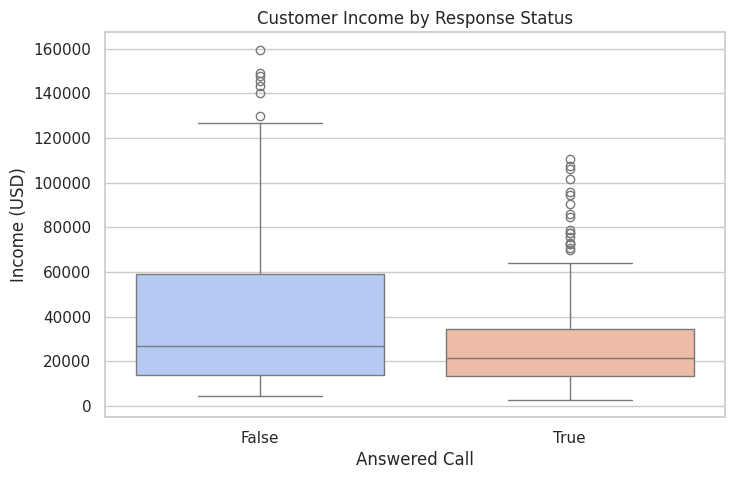

In [7]:
# Chart 3.1 🔧


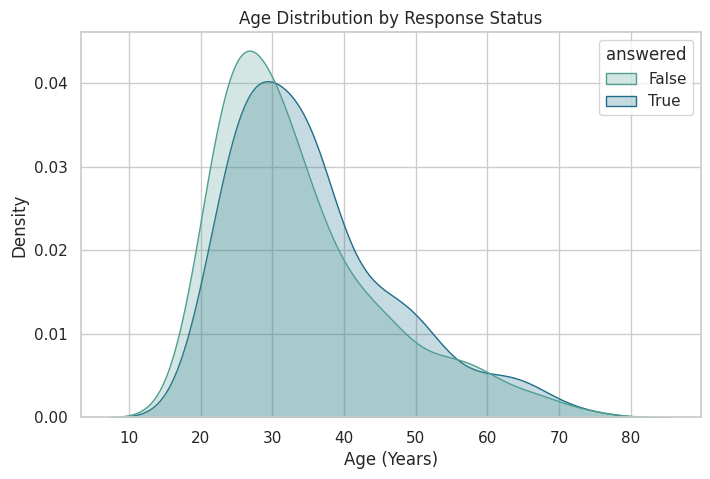

In [8]:
# Chart 3.2 🔧

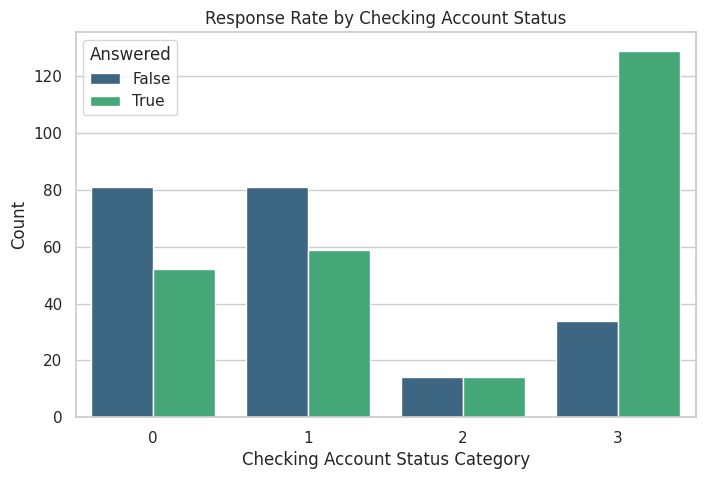

In [9]:
# Chart 3.3 🔧

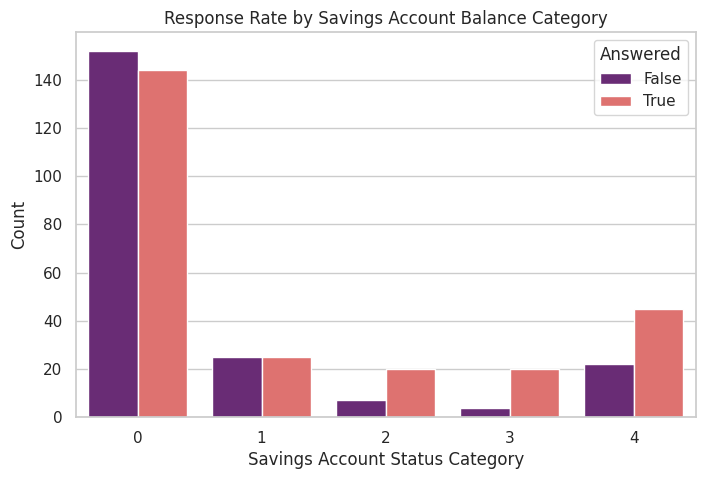

In [10]:
# Chart 3.4 🔧

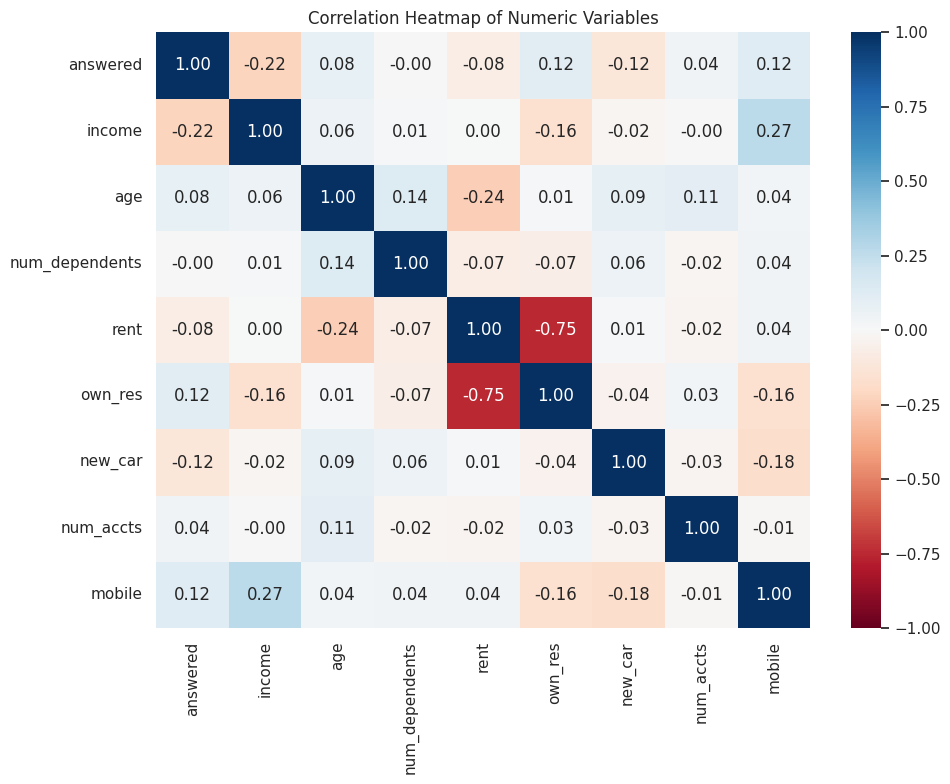

In [11]:
# Chart 3.5 🔧

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Based on the charts, income, checking account status, and savings account balance show the strongest relationships with whether a customer answers the phone. Income has a negative correlation of -0.22, meaning customers with higher incomes were somewhat less likely to answer. Customers with higher checking and savings account categories also appeared more likely to answer.

3.7. Yes, variables like age, number of dependents, and number of accounts showed very weak relationships with whether someone answered. Number of dependents had almost no correlation at all. However, I wouldn't remove them immediately because they might still help the model identify patterns when combined with other variables. I would test the model first before deciding whether to remove them.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

Total Customers: 464
Customers who Answered: 254
Base Probability of Answering: 0.5474 (54.74%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


X_train shape: (324, 12)
X_test shape: (140, 12)
y_train shape: (324,)
y_test shape: (140,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

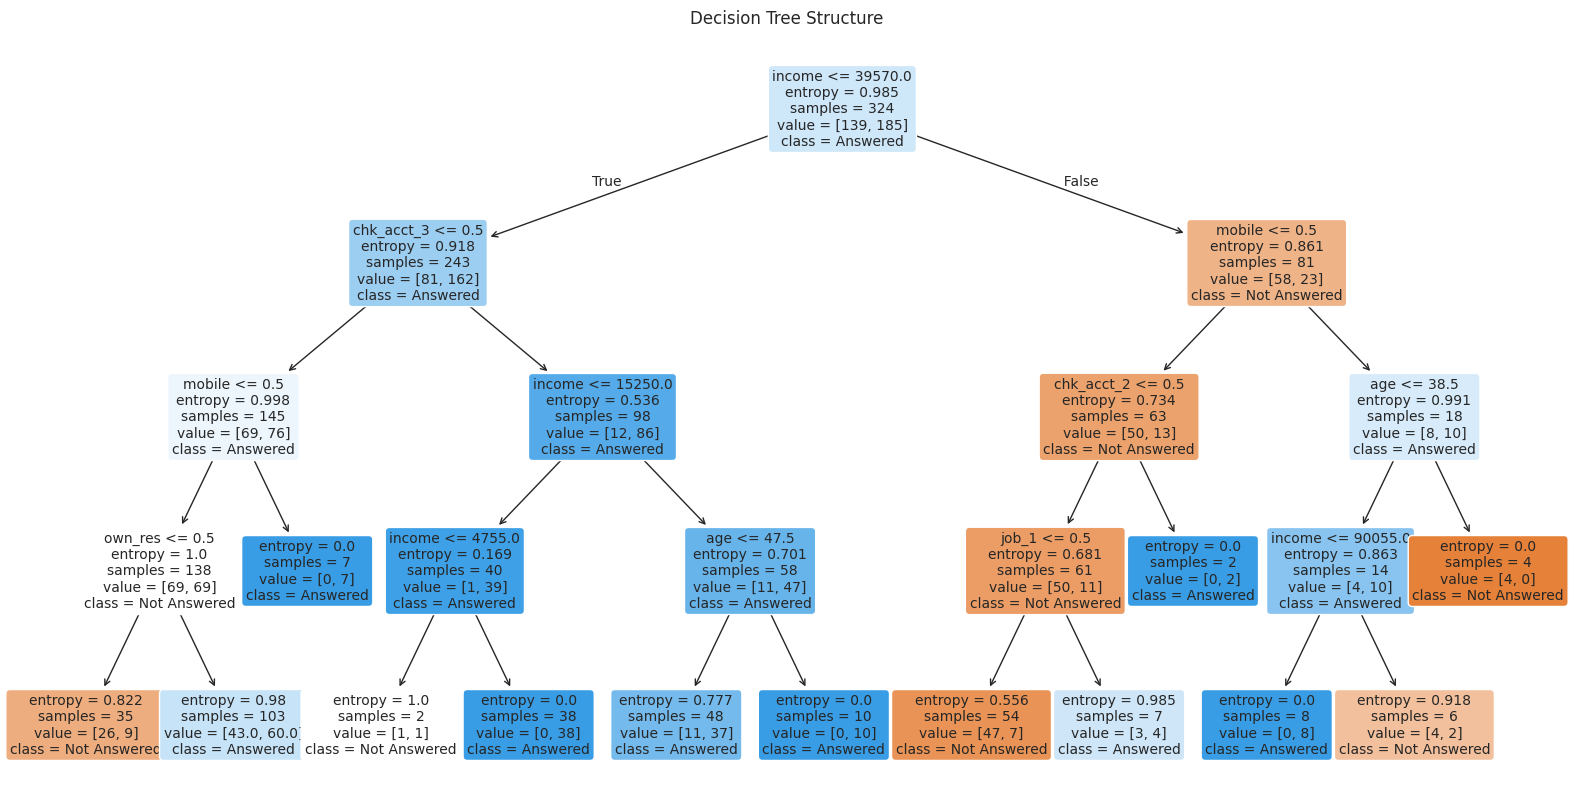

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

Base Probability of Answering: 0.5474 (54.74%)
Decision Tree Test Accuracy:  0.5714 (57.14%)

Success! The Decision Tree model outperforms the baseline probability.


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The base probability was 54.74%, while the decision tree model had an accuracy of 57.14%. This is an improvement of 2.40 percentage points, meaning the model is slightly better at predicting whether customers will answer their calls.

2. The improvement is pretty small, so it probably wouldn't make a huge difference for the business right now. However, even a small increase in accuracy could help reduce wasted time for sales representatives over a large number of calls. The company would need to compare profits to see if the model is actually worth using.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

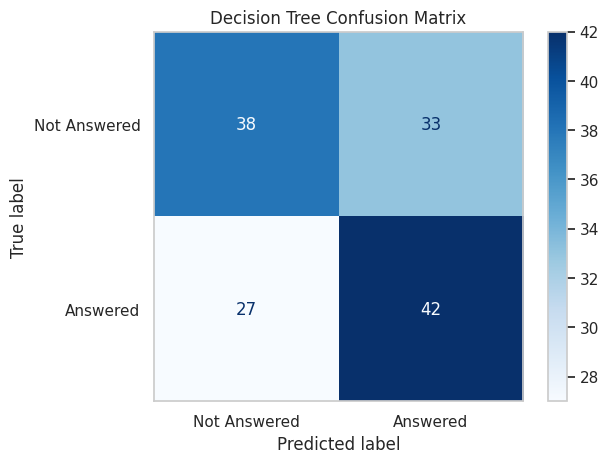

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

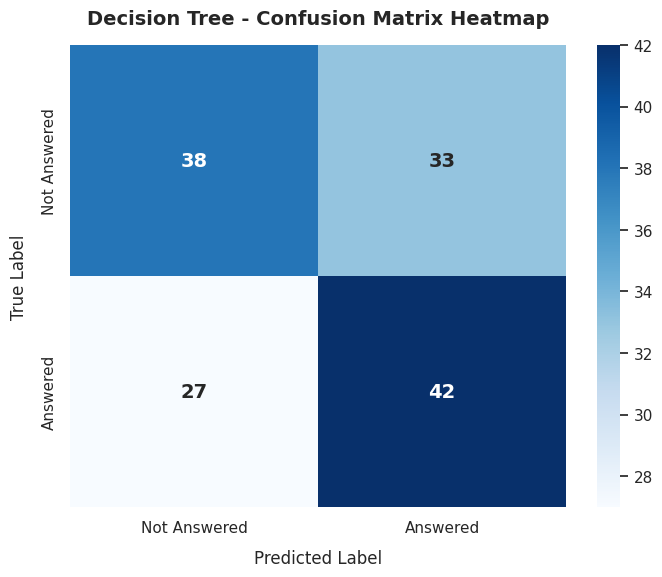

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

Decision Tree Training Accuracy: 0.7654 (76.54%)
Decision Tree Testing Accuracy:  0.5714 (57.14%)
Difference (Train - Test):        0.1940 (19.40%)


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. My model appears to be overfit because the training accuracy is 76.54%, while the testing accuracy is only 57.14%. That's a difference of 19.40 percentage points, meaning the model performs much better on the training data than on new data.
2. I could reduce the maximum depth of the decision tree or increase the minimum number of samples required for a split. This would make the tree less complex and hopefully improve its performance on new data.
3. If the model were underfit, I could increase the maximum depth of the tree or allow more splits. This would help the model identify more patterns in the data, but I would need to be careful not to make it overfit again.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

Test Set Confusion Matrix Breakdown:
True Positives (Predicted to Answer, and Answered):  42
False Positives (Predicted to Answer, but Didn't):   33
True Negatives (Predicted Not to Answer, and Didn't): 38
False Negatives (Predicted Not to Answer, but Did):   27
--------------------------------------------------
Estimated Profit using the Model: $2,325.00


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

Test Set Baseline Breakdown (Calling Everyone):
Actual Answers (True Positives):      69
Actual Non-Answers (False Positives): 71
--------------------------------------------------
Estimated Default Profit (No Model):  $3,400.00
Estimated Model Profit (Step 5.1):    $2,325.00
Net Profit Difference:                $-1,075.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling all customers resulted in an estimated profit of $3,400, while using the model resulted in $2,325. This is a difference of $1,075, meaning the company actually made more money by calling everyone instead of following the model's recommendations.

2. Yes, $1,075 is a pretty significant difference, especially since it represents about a 32% decrease in profit. This shows that even though the model improved prediction accuracy slightly, it isn't necessarily better for the business. The company would benefit more from calling everyone unless the model can be improved.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

Initial Decision Tree Test Accuracy: 57.14%
Tuned Decision Tree Train Accuracy:  72.53%
Tuned Decision Tree Test Accuracy:   54.29%
Difference (Train - Test):           18.25%


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random Forest Test Accuracy: 0.5929 (59.29%)


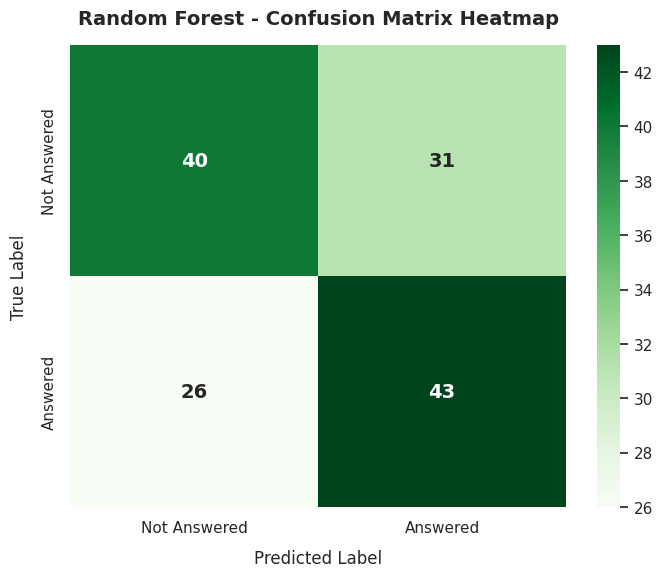

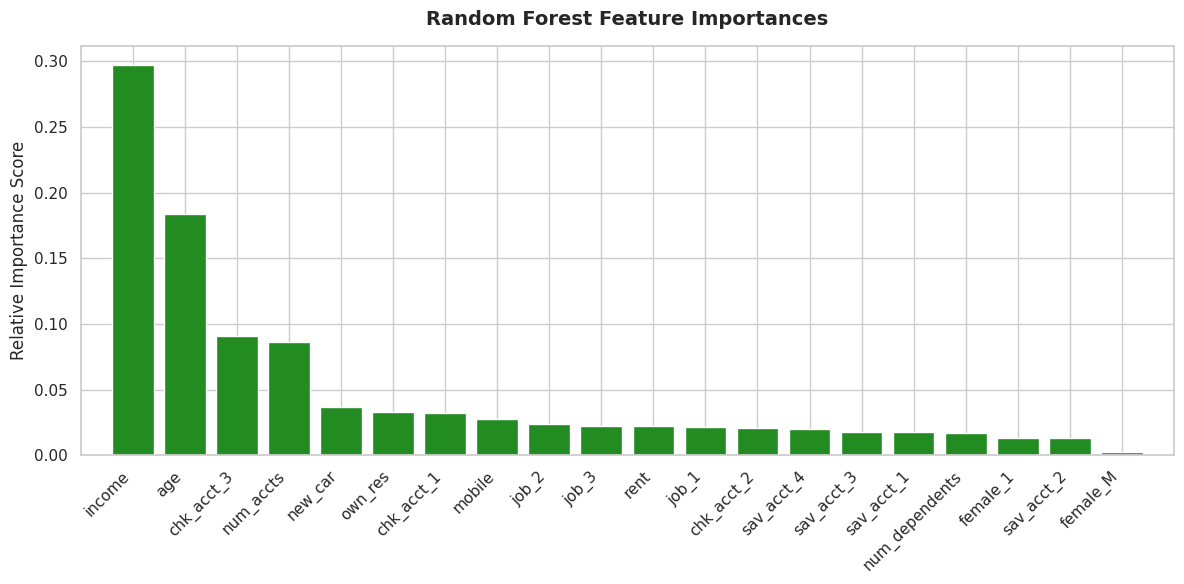

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest had a test accuracy of 59.29%, based on the confusion matrix. This is slightly higher than the original decision tree's 57.14%. However, I would need to compare it with the tuned decision tree's accuracy to know which performed better.
2. Income and age were the most important variables in the random forest, followed by checking account status and savings account balance. These were similar to the variables identified earlier in the analysis. This suggests that financial information and age play an important role in predicting whether customers answer their calls.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient Boosting Test Accuracy: 0.6071 (60.71%)


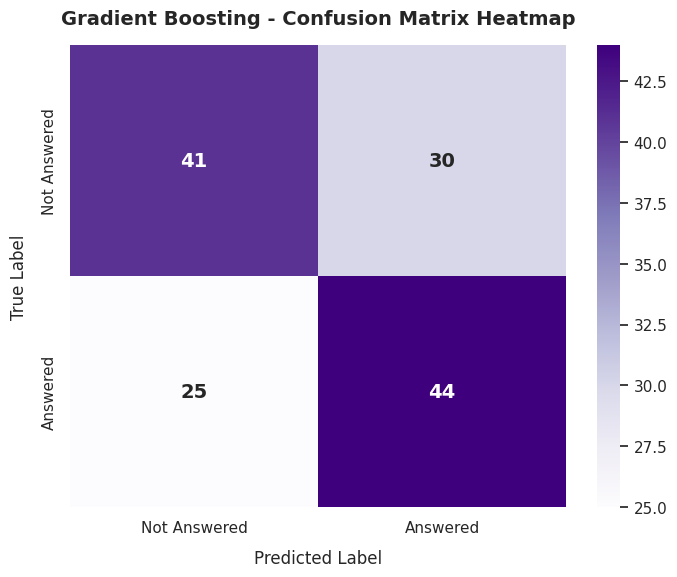

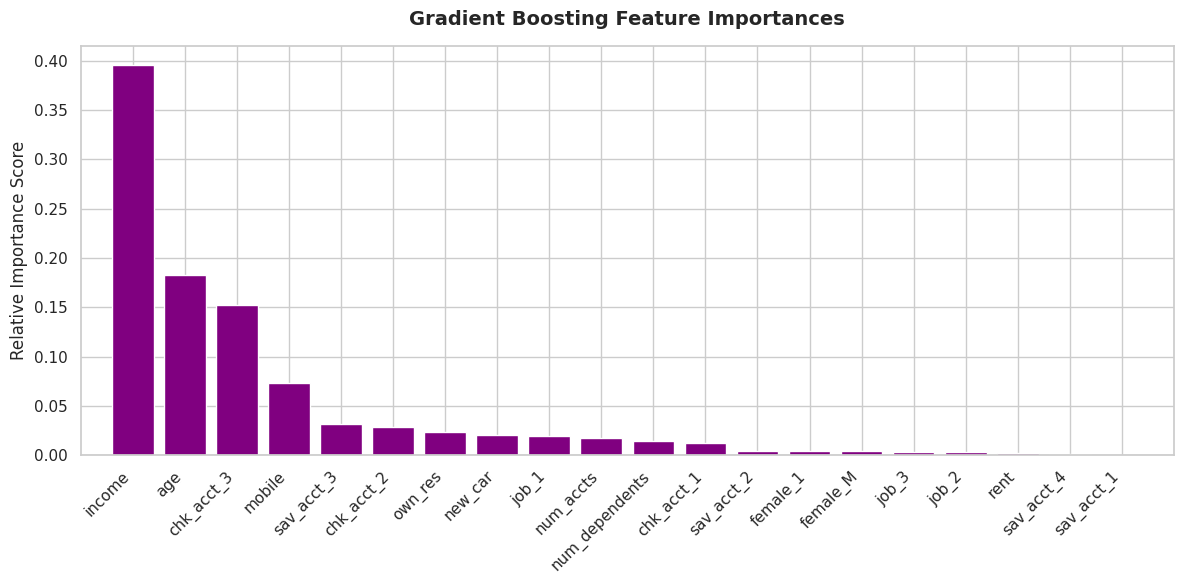

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. The gradient boosting model had slightly better test accuracy at 60.71%, compared to the random forest's 59.29%. This means gradient boosting performed a little better at predicting whether customers would answer their calls.
2. The main difference is how the models build their decision trees. Random forest creates multiple trees independently and combines their predictions to get a final answer. Gradient boosting builds trees one at a time, with each new tree trying to correct mistakes made by the previous ones. This can make gradient boosting more accurate, but it also requires careful tuning to avoid overfitting.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
0,Tuned Decision Tree,0.542857,40,35,2125
1,Random Forest,0.592857,43,31,2450
2,Gradient Boosting,0.607143,44,30,2550


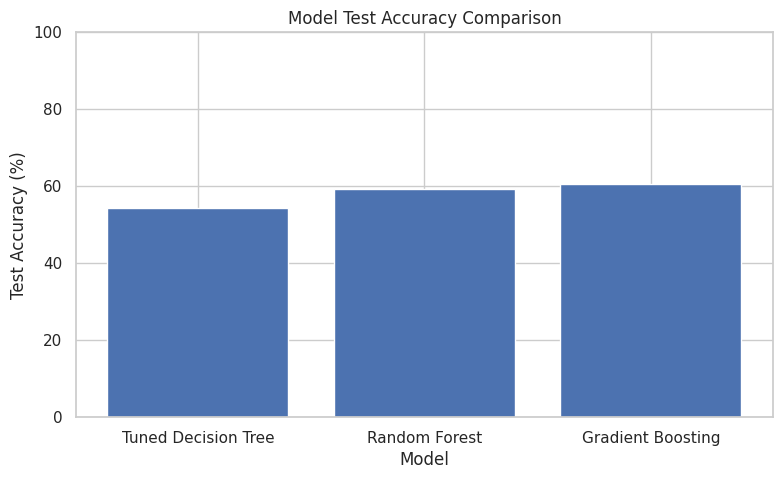

Recommended Model: Gradient Boosting
Test Accuracy: 60.71%
Estimated Profit: $2,550.00


In [29]:

# Step 5.6: Compare Models Using Accuracy and Profit

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

# Use the models trained in the previous steps
# If your model names differ, update these three variables
models = {
    'Tuned Decision Tree': tuned_dt_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    profit = (tp * 75) - (fp * 25)

    results.append({
        'Model': name,
        'Test Accuracy': accuracy,
        'True Positives': tp,
        'False Positives': fp,
        'Estimated Profit': profit
    })

# Create results table
model_results = pd.DataFrame(results)

display(model_results)

# Compare model accuracies
plt.figure(figsize=(9, 5))
plt.bar(
    model_results['Model'],
    model_results['Test Accuracy'] * 100
)

plt.title('Model Test Accuracy Comparison')
plt.ylabel('Test Accuracy (%)')
plt.xlabel('Model')
plt.ylim(0, 100)
plt.show()

# Recommend the model with the highest profit
# Use accuracy to break any ties
best_row = model_results.sort_values(
    ['Estimated Profit', 'Test Accuracy'],
    ascending=False
).iloc[0]

best_model_name = best_row['Model']
best_model = models[best_model_name]

print("Recommended Model:", best_model_name)
print("Test Accuracy:", f"{best_row['Test Accuracy']:.2%}")
print("Estimated Profit:", f"${best_row['Estimated Profit']:,.2f}")


=== SUMMARY OF MODEL COMPARISON ===


,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
0,Tuned Decision Tree,54.29%,40,35,"$2,125.00"
1,Random Forest,59.29%,43,31,"$2,450.00"
2,Gradient Boosting,60.71%,44,30,"$2,550.00"



=== FINAL BUSINESS RECOMMENDATION ===
Based on our evaluation on the test set, we recommend using the 'Gradient Boosting' model.
- Test Accuracy: 60.71%
- Expected Profit: $2,550.00
- True Positives (Successful Sales Calls): 44
- False Positives (Wasted Rep Time): 30


## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

Initial New Customer Data Shape: (1000, 13)

=== NEW CUSTOMERS PREDICTION RESULTS ===
Total New Customers Analyzed: 1000
Predicted to Answer (Yes):    565 (56.50%)
Predicted Not to Answer (No): 435 (43.50%)


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. Gradient boosting produced the highest estimated profit at $2,550. It was also the most accurate model with 60.71% accuracy, compared to 59.29% for random forest and 54.29% for the tuned decision tree.
 2. A business might choose a model with lower accuracy if it produces more profit or reduces costs. Accuracy doesn't always mean better financial results, especially when different types of prediction errors have different costs.
 3. The decision tree would be easiest to explain because it shows the specific steps used to make predictions. However, I would recommend gradient boosting because it had the highest accuracy and estimated profit out of the three models.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 No, the models did not improve profit compared to calling everyone. The best model, gradient boosting, produced $2,550 in estimated profit, while calling all customers produced $3,400. This means using the model resulted in $850 less profit.

6.2 The business could use the model to predict which customers are most likely to answer their scheduled calls. This could help sales representatives prioritize customers and improve scheduling efficiency. However, the company should continue improving the model before using it to decide which customers not to call, since calling everyone currently produces more profit.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"